In [184]:
import pandas as pd

#visualizaciones
import matplotlib.pyplot as plt
import seaborn as sns


In [185]:
#traigo archivos
df_bajas_agosto = pd.read_csv("../files/processed/bajas_agosto_2019.csv")
df_altas_agosto = pd.read_csv("../files/processed/altas_agosto_2019.csv")
df_plantilla_julio = pd.read_csv("../files/processed/plantilla_julio_2019.csv")

C:\Users\sarag\AppData\Local\Temp\ipykernel_20604\3716998798.py:4: DtypeWarning: Columns (0: Área Funcional, 1: Nacionalidad) have mixed types. Specify dtype option on import or set low_memory=False.
  df_plantilla_julio = pd.read_csv("../files/processed/plantilla_julio_2019.csv")


¿Está cumpliendo CORUSAN con la LISMI?

In [186]:
df_plantilla_julio.info()

<class 'pandas.DataFrame'>
RangeIndex: 48431 entries, 0 to 48430
Data columns (total 21 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Convenio Aplicable                                 23800 non-null  str    
 1   Localización País                                  48431 non-null  str    
 2   Área Funcional                                     15995 non-null  str    
 3   Localización Ciudad                                48431 non-null  str    
 4   Año                                                48431 non-null  int64  
 5   COD. UNIDAD DE NEGOCIO                             48431 non-null  int64  
 6   Mes                                                48431 non-null  str    
 7   Reducción de Jormada                               48431 non-null  str    
 8   División                                           48431 non-null  str    
 9   Subactividad     

In [187]:
df_plantilla_julio['Discapacidad'].head()

0    No
1    No
2    No
3    No
4    No
Name: Discapacidad, dtype: str

In [188]:

# analizamos la columna para ver % 

In [189]:

resumen_discapacidad = pd.DataFrame({
    'Conteo': df_plantilla_julio['Discapacidad'].value_counts(dropna=False),
    'Porcentaje (%)': (
        df_plantilla_julio['Discapacidad'].value_counts(
            normalize=True, dropna=False
        )
        * 100
    ).round(2),
})

display(resumen_discapacidad)

,Conteo,Porcentaje (%)
Discapacidad,,
No,47978,99.06
Sí,453,0.94


In [190]:
conteo= len(df_plantilla_julio)
conteo

48431

In [191]:
# no cumple con el LISMI, para los trabajadores de  España, ya que en empresas mayores de 50 empleados minimo es el 2% esta empresa cuenta con 48431 personas
# y solo tiene el 0.94%
# no cumple con el LISMI, para los trabajadores de  Brasil, ya que en empresas mayores de 1000 empleados minimo es el 5% esta empresa cuenta con 48431 personas
# y solo tiene el 0.94%


In [192]:
# creo una lista con las personas discapacitadas para estudiarles (PD)
PD= df_plantilla_julio[df_plantilla_julio['Discapacidad'].astype(str).str.strip().str.upper() == 'SÍ']

PD.head()

,Convenio Aplicable,Localización País,Área Funcional,Localización Ciudad,Año,COD. UNIDAD DE NEGOCIO,Mes,Reducción de Jormada,División,Subactividad,...,Departamento,HORAS TEÓRICAS SEMANALES POR UNIDAD DE NEGOCIO,Nombre del puesto,Nacionalidad,PROMEDIO DE HORAS SEMANALES TRABAJADAS EN EL MES,Fecha de Nacimiento,Clase de empleado,Discapacidad,Fecha de Alta,ID persona
99,Sí,España,Red - Planificación Tecnológica,MADRID,2019,156,Jul,No,"OPERACIONES, RED Y TI",Tecnología y Planificación,...,ESTRAT. Y DESARR. DE RED E INFRAESTR. TI,37.5,EXPERTO NIVEL 1,ESPAÑOLA,37.5,1986-05-05,EMP,Sí,2013-01-08,1716951
204,Sí,España,Red - Planificación Tecnológica,MADRID,2019,156,Jul,No,"OPERACIONES, RED Y TI",Tecnología y Planificación,...,ESTRAT. Y DESARR. DE RED E INFRAESTR. TI,37.5,EXPERTO NIVEL 2,ESPAÑOLA,37.5,1966-07-26,EMP,Sí,2008-05-26,1717056
632,Sí,España,Red - Control de Operaciones de Red,SEVILLA,2019,156,Jul,No,"OPERACIONES, RED Y TI",Supervisión de red,...,"SOPORTE Y EXPL. RED,SERVICIOS Y SISTEMAS",37.5,ENCARGADO DE OPERACION,ESPAÑOLA,37.5,1969-09-30,EMP,Sí,1991-12-11,1717484
691,Sí,España,Op. Comerciales - Soporte de Operaciones de Ve...,BALEARES,2019,156,Jul,No,CONSEJERA DELEGADA COO,Soporte ventas,...,GRAN PUBLICO,37.5,RESPONSABLE VENTAS 1 BASE,ESPAÑOLA,37.5,1971-02-27,EMP,Sí,1990-12-19,1717543
936,Sí,España,Red - Control de Operaciones de Red,MADRID,2019,156,Jul,No,"OPERACIONES, RED Y TI",Soporte de Red,...,POSTVENTA,37.5,TITULADO/TECNICO MEDIO O DE GRADO,ESPAÑOLA,37.5,1958-04-08,EMP,Sí,1989-07-17,1717788


In [193]:
cantidad_PD=len(PD)

In [194]:

tabla_genero_PD = pd.DataFrame({
    'Cantidad': PD['Género'].value_counts(dropna=False),
    'Porcentaje (%)': (
        PD['Género'].value_counts(normalize=True, dropna=False) * 100
    ).round(2),
})

print(f'La cantidad total de personas discapacitadas es: {cantidad_PD}\n')
display(tabla_genero_PD)

La cantidad total de personas discapacitadas es: 453



,Cantidad,Porcentaje (%)
Género,,
M,286,63.13
F,167,36.87


In [195]:
# por paises

In [196]:
crosstab_genero = pd.crosstab(PD['Localización País'], PD['Género'], normalize='index') * 100

# Renombramos las columnas para que quede claro (% Mujeres y % Hombres - ajusta 'F' o 'M' según cómo se llamen en tus datos)

crosstab_genero = crosstab_genero.rename( columns={'F': '% Mujeres', 'M': '% Hombres'}).round(2)

# 2. Montamos la tabla final combinando la cantidad total por país, el % global y los porcentajes por género
tabla_pais_completa = pd.DataFrame({
    'Cantidad': PD['Localización País'].value_counts(),
    'Porcentaje Global (%)': (
        PD['Localización País'].value_counts(normalize=True) * 100
    ).round(2),
})

# Unimos los porcentajes de género por país
tabla_pais_completa = tabla_pais_completa.join(crosstab_genero)

# 3. Mostramos el resultado final limpio
print(f'La cantidad total de personas discapacitadas es: {cantidad_PD}\n')
display(tabla_pais_completa)

La cantidad total de personas discapacitadas es: 453



,Cantidad,Porcentaje Global (%),% Mujeres,% Hombres
Localización País,,,,
Brasil,311,68.65,38.26,61.74
España,142,31.35,33.80,66.20


In [197]:
# como se calcula el % dependiendo de los trabajadores de ese país, debemos calcular 
# los trabajadores con discapacidad según el país 

In [198]:
df_plantilla_julio[['Discapacidad','Localización País']].value_counts()

Discapacidad  Localización País
No            Brasil               32101
              España               15877
Sí            Brasil                 311
              España                 142
Name: count, dtype: int64

In [199]:


porcentaje_por_pais = (
    pd.crosstab(
        df_plantilla_julio['Localización País'],
        df_plantilla_julio['Discapacidad'],
        normalize='index',
    )
    * 100
).round(2)

display(porcentaje_por_pais)

Discapacidad,No,Sí
Localización País,,
Brasil,99.04,0.96
España,99.11,0.89


In [200]:
#recordamos que en Brasil es más de un 5% y en España al menos un 2% en ninguno de los 2 se cumple 

--- DIAGNÓSTICO DE CUMPLIMIENTO LISMI / LGD & LEY BRASILEÑA ---
ESPAÑA -> Plantilla: 16019 | Actual PD: 142 | Faltan (Gap): int(round(178.38)) personas
BRASIL -> Plantilla: 32412 | Actual PD: 311 | Faltan (Gap): int(round(337.24)) personas



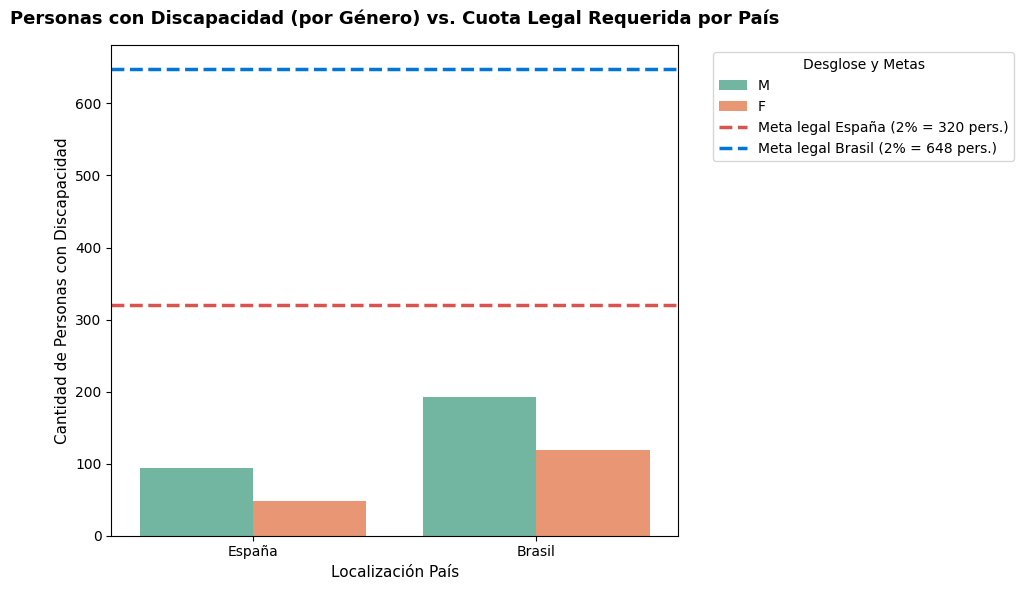

In [201]:


# 1. PLANTILLA TOTAL POR PAÍS (ejemplo usando tu DataFrame general, ej: df_plantilla_julio)
# Calculamos el total de trabajadores por país
total_empleados_pais = df_plantilla_julio['Localización País'].value_counts()

# 2. PERSONAS CON DISCAPACIDAD (PD) ACTUALES POR PAÍS
pd_actual_pais = PD['Localización País'].value_counts()

# 3. CÁLCULO DE OBJETIVOS LEGALES
# España: 2% fijo sobre su plantilla total en España
# Brasil: escala según tamaño (ej. si están en el tramo del 2% al 5%, aplicamos el % correspondiente, ej: 2% o el que corresponda a su volumen)
objetivo_espana_num = total_empleados_pais.get('España', 0) * 0.02
# Supongamos el % aplicable en Brasil según su tramo (ej. 2% o el que marque su escala de plantilla)
porcentaje_brasil_ley = (
    0.02  # Ajusta este valor (0.02 a 0.05) según el tramo de su plantilla en Brasil
)
objetivo_brasil_num = (
    total_empleados_pais.get('Brasil', 0) * porcentaje_brasil_ley
)

# 4. CÁLCULO DE LA BRECHA (GAP) = Cuota legal requerida - Personas actuales con discapacidad
gap_espana = max(0, objetivo_espana_num - pd_actual_pais.get('España', 0))
gap_brasil = max(0, objetivo_brasil_num - pd_actual_pais.get('Brasil', 0))

print(f'--- DIAGNÓSTICO DE CUMPLIMIENTO LISMI / LGD & LEY BRASILEÑA ---')
print(
    f'ESPAÑA -> Plantilla: {total_empleados_pais.get("España", 0)} | Actual PD: {pd_actual_pais.get("España", 0)} | Faltan (Gap): int(round({gap_espana})) personas'
)
print(
    f'BRASIL -> Plantilla: {total_empleados_pais.get("Brasil", 0)} | Actual PD: {pd_actual_pais.get("Brasil", 0)} | Faltan (Gap): int(round({gap_brasil})) personas\n'
)

# 5. GRÁFICO DE BARRAS CON LÍNEAS DE OBJETIVO LEGAL
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=PD, x='Localización País', hue='Género', palette='Set2')

# Añadimos las líneas horizontales con las metas legales reales de cada país
# Nota: Como el gráfico compara conteos absolutos, las líneas representan el número objetivo de personas (cuota legal en nº de empleados)
plt.axhline(
    y=objetivo_espana_num,
    color='#d9534f',
    linestyle='--',
    linewidth=2.5,
    label=f'Meta legal España (2% = {int(round(objetivo_espana_num))} pers.)',
)
plt.axhline(
    y=objetivo_brasil_num,
    color='#0275d8',
    linestyle='--',
    linewidth=2.5,
    label=(
        f'Meta legal Brasil ({int(porcentaje_brasil_ley*100)}% ='
        f' {int(round(objetivo_brasil_num))} pers.)'
    ),
)

plt.title(
    'Personas con Discapacidad (por Género) vs. Cuota Legal Requerida por País',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Localización País', fontsize=11)
plt.ylabel('Cantidad de Personas con Discapacidad', fontsize=11)
plt.legend(title='Desglose y Metas', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# 2 Bajas en agosto

In [202]:
#2.  Realiza un análisis del tipo de bajas que se han producido durante el mes de Agosto
#por tipo de:
#   puesto de trabajo, 
#   rangos de edad, 
#   género 
#   zona geográfica.

In [203]:
df_bajas_agosto.head()

,ID persona,Unidad de Negocio,COD. UNIDAD DE NEGOCIO,Subactividad_desc,Subactividad,Genero,Fecha nacimiento,Fecha fin de contrato,Tipo de baja local,Tipo de baja global,Nombre del puesto
0,1716855,España,156,tecnologíayplanificación,Tecnología y Planificación,M,1952-02-12,2019-08-10,b.2) Otras bajas vegetativas,b.2) Otras bajas vegetativas,TITULADO SUPERIOR O MASTER
1,1716863,España,156,gestionydireccion,Gestión y Direccion,F,1952-02-12,2019-08-10,b.2) Otras bajas vegetativas,b.2) Otras bajas vegetativas,TITULADO SUPERIOR O MASTER
2,1716872,España,156,vigilanciayseguridad,Vigilancia y Seguridad,M,1989-09-14,2019-08-11,b.1) Renuncias voluntarias,b.1) Renuncias voluntarias,TITULADO/TECNICO MEDIO O DE GRADO
3,1716873,España,156,vigilanciayseguridad,Vigilancia y Seguridad,F,1988-09-06,2019-08-19,b.1) Renuncias voluntarias,b.1) Renuncias voluntarias,EXPERTO NIVEL 2
4,1716956,España,156,tecnologíayplanificación,Tecnología y Planificación,M,1966-12-01,2019-08-21,b.1) Renuncias voluntarias,b.1) Renuncias voluntarias,TITULADO SUPERIOR O MASTER


In [204]:
# veremos numero de bajas

In [205]:
print (f'se han producido :',len(df_bajas_agosto), 'bajas en agosto \n',
       f'--------------------------------------------------------------','\n',
       f'han sido por los siguientes motivos:', df_bajas_agosto['Tipo de baja global'].value_counts(), '\n',
       f'---------------------------------------------------------------','\n',
       f'han sido por los siguientes motivos:', df_bajas_agosto['Tipo de baja local'].value_counts(), '\n',
              f'---------------------------------------------------------------','\n',
       f'por generos las bajas han sido de esta forma', df_bajas_agosto['Genero'].value_counts(),'\n',
       f'---------------------------------------------------------------','\n',
       f'por paises ', df_bajas_agosto['Unidad de Negocio'].value_counts(), 
       f'---------------------------------------------------------------','\n', )


se han producido : 360 bajas en agosto 
 -------------------------------------------------------------- 
 han sido por los siguientes motivos: Tipo de baja global
a.2 ) X otras causas (Indemnizaciones)    290
b.1) Renuncias voluntarias                 68
b.2) Otras bajas vegetativas                2
Name: count, dtype: int64 
 --------------------------------------------------------------- 
 han sido por los siguientes motivos: Tipo de baja local
Dispensa sem Justa Causa AVP Inden.    265
Pedido Demissão                         54
Dispensa Com Justa Causa                16
Pedido Dem na Experiência               10
Antes Termino Contrato                   7
b.1) Renuncias voluntarias               4
b.2) Otras bajas vegetativas             2
Falecimento morte natural                2
Name: count, dtype: int64 
 --------------------------------------------------------------- 
 por generos las bajas han sido de esta forma Genero
M    210
F    150
Name: count, dtype: int64 
 -------------

In [206]:
#Destacamos que:
# mayoritariamente las bajas son en brasil asi que las 6 dde españa de momento la descarto 
# que 290 son con indepnizaciones que voluntarias 68 y 2 vegetativas ,
# que son mas despedidos los hombre 210 frente a 150 
# el tipo de despido que hay que traducirlo porque esta en portugues , 
# me faltaria saber el puesto y la ciudad de brasil , 

In [207]:
df_bajas_agosto_copy=df_bajas_agosto # se hace una copia

In [208]:
# 1. Definimos el diccionario de traducción
traduccion_bajas = {
    'Dispensa sem Justa Causa AVP Inden.': (
        'Despido improcedente / sin causa (con indemnización)'
    ),
    'Pedido Demissão': 'Renuncia voluntaria / Dimisión',
    'Dispensa Com Justa Causa': 'Despido disciplinario / con causa',
    'Pedido Dem na Experiência': 'Renuncia en periodo de prueba',
    'Antes Termino Contrato': 'Extinción anticipada de contrato',
    'Falecimento morte natural': 'Fallecimiento por causa natural',
}

# 2. Sobrescribimos (pisamos) directamente la columna original de bajas locales en el DataFrame
df_bajas_agosto['Tipo de baja local'] = (
    df_bajas_agosto_copy['Tipo de baja local']
    .map(traduccion_bajas)
    .fillna(df_bajas_agosto_copy['Tipo de baja local'])
)

# 3. Comprobamos el resultado directamente con la columna ya traducida
conteo_traducido = pd.DataFrame({
    'Cantidad': df_bajas_agosto_copy['Tipo de baja local'].value_counts(dropna=False),
    'Porcentaje (%)': (
        df_bajas_agosto_copy['Tipo de baja local'].value_counts(
            normalize=True, dropna=False
        )
        * 100
    ).round(2),
})
display(conteo_traducido)

,Cantidad,Porcentaje (%)
Tipo de baja local,,
Despido improcedente / sin causa (con indemnización),265,73.61
Renuncia voluntaria / Dimisión,54,15.00
Despido disciplinario / con causa,16,4.44
Renuncia en periodo de prueba,10,2.78
Extinción anticipada de contrato,7,1.94
b.1) Renuncias voluntarias,4,1.11
b.2) Otras bajas vegetativas,2,0.56
Fallecimiento por causa natural,2,0.56


In [209]:
# sacamos % de despedidos entre hombres y mujeres por cada casuistica 
porcentaje_genero_por_baja = (
    pd.crosstab(
        df_bajas_agosto_copy['Tipo de baja local'],
        df_bajas_agosto_copy['Genero'],
        normalize='index',
    )
    * 100
).round(2)

# Mostramos el resultado limpio
display(porcentaje_genero_por_baja)

Genero,F,M
Tipo de baja local,,
Despido disciplinario / con causa,31.25,68.75
Despido improcedente / sin causa (con indemnización),39.25,60.75
Extinción anticipada de contrato,57.14,42.86
Fallecimiento por causa natural,50.00,50.00
Renuncia en periodo de prueba,70.00,30.00
Renuncia voluntaria / Dimisión,48.15,51.85
b.1) Renuncias voluntarias,50.00,50.00
b.2) Otras bajas vegetativas,50.00,50.00


In [210]:
# sacamos % de despedidos por puesto  por cada casuistica 
porcentaje_genero_por_baja = (
    pd.crosstab(
        df_bajas_agosto_copy['Tipo de baja local'],
        df_bajas_agosto_copy['Subactividad'],
        normalize='index',
    )
    * 100
).round(2)

# Mostramos el resultado limpio
display(porcentaje_genero_por_baja.T)

Tipo de baja local,Despido disciplinario / con causa,Despido improcedente / sin causa (con indemnización),Extinción anticipada de contrato,Fallecimiento por causa natural,Renuncia en periodo de prueba,Renuncia voluntaria / Dimisión,b.1) Renuncias voluntarias,b.2) Otras bajas vegetativas
Subactividad,,,,,,,,
Administración y gestión de cobros,0.00,2.26,0.00,0.0,0.0,0.00,0.0,0.0
Aplicaciones/Desarrollo,0.00,0.75,0.00,0.0,0.0,1.85,0.0,0.0
Aseguramiento de ingresos y control de fraude,0.00,1.13,0.00,0.0,0.0,0.00,0.0,0.0
Asesoría legal y soporte jurídico,0.00,0.38,0.00,0.0,0.0,1.85,0.0,0.0
Calidad y Optimización de procesos,0.00,0.75,0.00,0.0,0.0,1.85,0.0,0.0
Call Center técnico,18.75,27.17,42.86,0.0,10.0,33.33,0.0,0.0
Canal telefónico - Atención,6.25,9.06,14.29,0.0,10.0,14.81,0.0,0.0
"Compensación, Beneficios y Movilidad Global",0.00,1.51,0.00,0.0,0.0,1.85,0.0,0.0
Compras,0.00,0.75,0.00,0.0,10.0,0.00,0.0,0.0


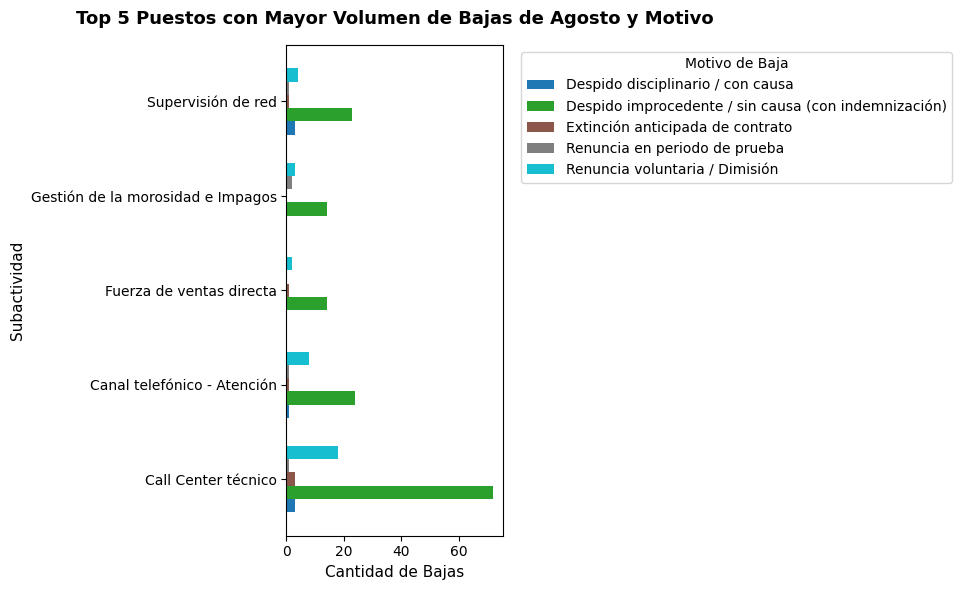

In [211]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Identificamos los 5 puestos con mayor número de bajas
top_5_puestos = df_bajas_agosto_copy['Subactividad'].value_counts().head(5).index

# 2. Filtramos el DataFrame original para quedarnos solo con esos 5 puestos principales
df_top_5 = df_bajas_agosto_copy[df_bajas_agosto_copy['Subactividad'].isin(top_5_puestos)]

# 3. Creamos la tabla cruzada para estos 5 puestos y el motivo de baja traducido
tabla_top5 = pd.crosstab(
    df_top_5['Subactividad'],
    df_top_5['Tipo de baja local']
)

# 4. Generamos el gráfico de barras horizontales
ax = tabla_top5.plot(kind='barh', figsize=(10, 6), colormap='tab10', width=0.7)

# 5. Formato directivo y estético
plt.title('Top 5 Puestos con Mayor Volumen de Bajas de Agosto y Motivo', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Cantidad de Bajas', fontsize=11)
plt.ylabel('Subactividad', fontsize=11)

# Leyenda y diseño limpio
plt.legend(title='Motivo de Baja', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

In [ ]:
df_bajas_agosto_copy[['Subactividad','Tipo de baja local']].value_counts()# aqui vemos los 5 con mas despidos y los 3 con menos

Subactividad                       Tipo de baja local                                  
Call Center técnico                Despido improcedente / sin causa (con indemnización)    72
Canal telefónico - Atención        Despido improcedente / sin causa (con indemnización)    24
Supervisión de red                 Despido improcedente / sin causa (con indemnización)    23
Call Center técnico                Renuncia voluntaria / Dimisión                          18
Gestión de la morosidad e Impagos  Despido improcedente / sin causa (con indemnización)    14
                                                                                           ..
Fuerza de ventas directa           Extinción anticipada de contrato                         1
Soporte ventas                     Despido improcedente / sin causa (con indemnización)     1
Canal telefónico - Atención        Extinción anticipada de contrato                         1
                                   Despido disciplinario / con cau

In [213]:
df_bajas_agosto_copy['Tipo de baja local'].value_counts() # con indepnizacion 265 mientras que renuncias solo 54  solo esto son 319 el resto son solo 35 personas

Tipo de baja local
Despido improcedente / sin causa (con indemnización)    265
Renuncia voluntaria / Dimisión                           54
Despido disciplinario / con causa                        16
Renuncia en periodo de prueba                            10
Extinción anticipada de contrato                          7
b.1) Renuncias voluntarias                                4
b.2) Otras bajas vegetativas                              2
Fallecimiento por causa natural                           2
Name: count, dtype: int64

In [ ]:
df_bajas_agosto_copy[['Tipo de baja local','Genero']].value_counts()# vemos que `por genero y tipo de despido  no hay grandes diferencias `

Tipo de baja local                                    Genero
Despido improcedente / sin causa (con indemnización)  M         161
                                                      F         104
Renuncia voluntaria / Dimisión                        M          28
                                                      F          26
Despido disciplinario / con causa                     M          11
Renuncia en periodo de prueba                         F           7
Despido disciplinario / con causa                     F           5
Extinción anticipada de contrato                      F           4
Renuncia en periodo de prueba                         M           3
Extinción anticipada de contrato                      M           3
b.1) Renuncias voluntarias                            M           2
                                                      F           2
b.2) Otras bajas vegetativas                          M           1
                                                      F

In [215]:
df_bajas_agosto_copy = pd.merge(
    df_bajas_agosto_copy,
    df_plantilla_julio[
        ['ID persona', 'Localización Ciudad']
    ],  # Seleccionamos la clave y la ciudad de la plantilla
    on='ID persona',  # Columna común para relacionarlos
    how='left',  # Merge por la izquierda para conservar todas las bajas de agosto
)

# 2. Filtramos de nuevo las bajas de Brasil ya con la ciudad incorporada
df_bajas_brasil_copy = df_bajas_agosto_copy[
    df_bajas_agosto_copy['Unidad de Negocio'] == 'Brasil'
]

from scr.funciones_analisis import limpiar_ciudades

# Llamas a la función en la siguiente línea asignándola a tu DataFrame
df_bajas_brasil_copy = limpiar_ciudades(
    df_bajas_brasil_copy, 'Localizacion ciudad'
)

# 3. Limpiamos usando el nombre exacto de la columna (con tilde)
df_bajas_brasil_copy = limpiar_ciudades(
    df_bajas_brasil_copy, 'Localización Ciudad'
)
df_bajas_brasil_copy.columns


Aviso: La columna 'Localizacion ciudad' no se encuentra en el DataFrame.
¡Columna 'Localización Ciudad' normalizada a minúsculas y sin tildes con éxito!


Index(['ID persona', 'Unidad de Negocio', 'COD. UNIDAD DE NEGOCIO',
       'Subactividad_desc', 'Subactividad', 'Genero', 'Fecha nacimiento',
       'Fecha fin de contrato', 'Tipo de baja local', 'Tipo de baja global',
       'Nombre del puesto', 'Localización Ciudad'],
      dtype='str')

In [216]:

# 4. Comprobamos la distribución de bajas por Ciudad y Motivo
tabla_ere_ciudad = pd.crosstab(
    df_bajas_brasil_copy['Localización Ciudad'],
    df_bajas_brasil_copy['Tipo de baja local'],
    margins=True,
)

print('--- ANÁLISIS DE BAJAS POR CIUDAD EN BRASIL (TRAS MERGE) ---')
display(tabla_ere_ciudad)

--- ANÁLISIS DE BAJAS POR CIUDAD EN BRASIL (TRAS MERGE) ---


Tipo de baja local,Despido disciplinario / con causa,Despido improcedente / sin causa (con indemnización),Extinción anticipada de contrato,Fallecimiento por causa natural,Renuncia en periodo de prueba,Renuncia voluntaria / Dimisión,All
Localización Ciudad,,,,,,,
aracaju,0,2,0,0,0,0,2
belo horizonte,1,6,0,0,0,0,7
brasilia,0,1,0,0,0,0,1
campinas,0,3,0,0,0,0,3
curitiba,0,43,1,0,0,8,52
goiania,0,0,0,0,0,1,1
porto alegre,0,1,0,0,0,0,1
ribeirao preto,0,1,0,0,0,0,1
rio de janeiro,0,8,0,0,1,1,10


In [ ]:
#llama la atencion sao paulo 

In [224]:
# 1. Asegurarnos de que las columnas de fecha sean de tipo fecha (datetime)
df_bajas_brasil_copy['Fecha nacimiento'] = pd.to_datetime(
    df_bajas_brasil_copy['Fecha nacimiento']
)
df_bajas_brasil_copy['Fecha baja'] = pd.to_datetime(
    df_bajas_brasil_copy['Fecha fin de contrato']
)

# 2. Calcular la edad en el momento de la baja
df_bajas_brasil_copy['Edad'] = (
    df_bajas_brasil_copy['Fecha baja'] - df_bajas_brasil_copy['Fecha nacimiento']
).dt.days // 365

# 3. Comprobamos la distribución de bajas por Edad y Motivo
df_bajas_brasil_copy['Edad'].value_counts()

print('--- ANÁLISIS DE BAJAS POR EDAD EN BRASIL ---')
display(tabla_ere_edad)

--- ANÁLISIS DE BAJAS POR EDAD EN BRASIL ---


Tipo de baja local,Despido disciplinario / con causa,Despido improcedente / sin causa (con indemnización),Extinción anticipada de contrato,Fallecimiento por causa natural,Renuncia en periodo de prueba,Renuncia voluntaria / Dimisión,All
Edad,,,,,,,
19,2,1,0,0,0,1,4
20,1,4,0,0,0,2,7
21,1,2,0,0,0,1,4
22,1,4,0,0,1,3,9
23,3,7,0,0,0,0,10
24,0,13,2,0,0,2,17
25,1,7,1,0,0,3,12
26,3,15,0,0,0,2,20
27,1,14,0,1,1,2,19


Queda demostrado que las bajas son:

1) Sobre todo en Brasil de las 360 bajas totales 354 son en Brasil
2) Hombres 210 sobre mujeres 150
3) 73.61% (256 bajas)son despido improcedente con indepnizacion
    15% son renuncia voluntaria
4) lo que mas se hace es despido imporcedente en call center tecnico seguido de canal teledonico de atencio, seguido de renuncia call center tecnico
5) Por generos no llama la atencion en ningun caso
6) Si llama la atencion que es en Sao paulo donde mas se despide , con amplia mayoria sobre los demás , lo que da lugar a pensar en un ERE o ERTE 
7) las personas más despedidas tenian 33 años seguidos de las personas de 37 años 

por lo tanto el perfil más despedido es :

 Personal Brasileño de Sao Paolo en los departamentos de: 

            Call Center técnico                Despido improcedente / sin causa (con indemnización)    72
            Canal telefónico - Atención        Despido improcedente / sin causa (con indemnización)    24
            Supervisión de red                 Despido improcedente / sin causa (con indemnización)    23
            Call Center técnico                Renuncia voluntaria / Dimisión                          18
            Gestión de la morosidad e Impagos  Despido improcedente / sin causa (con indemnización)    14

sin tanta importancia hombres de 33 o 37 años 

se propone revisar condiciones e call center tecnico  y canal telfonico de atencion

# 3. Caracteriza a la persona tipo que más rotación tiene (hombre/mujer de entre x e y años de áreas x,y,z de España / Brasil).